# Fixed 16 MW data center: graded reliability rejection

Original Parallel EGO sizes wind, PV, battery power and duration. The separate EMS maximizes availability; the outer evaluator enforces the reliability target. Native generation and economics are unchanged. The objective is annualized HPP cost divided by delivered **facility** energy, including partial supply. Below-target dispatches and solver bounds are retained. The EMS certificate concerns exact-service hours; reported reliability uses the existing tolerance.

Each run creates a new timestamped experiment under `hpp_sizing_runs/lcoe_reliability_frontier_graded_max_reliability`. Native checkpoints, logs and hourly results are retained inside each target folder. Time-limited results are validated incumbents, not global-optimality certificates.

Validated below-target candidates receive `M + gamma * LCoE_ref * excess_failed_hours / (8760 - H_max)`. Feasible candidates retain their actual LCoE. Invalid evaluations receive a worse finite score, with no fabricated reliability. Final selection always requires independently validated reliability. `score` is the negative adapter output; `ego_objective_score` is the quantity EGO minimizes. Exact-service certificates do not generally prove infeasibility under the reported numerical tolerance.


In [1]:
import os
os.environ['OPENMDAO_REPORTS'] = '0'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
from pathlib import Path
import matplotlib.pyplot as plt
import hydesign
from hydesign.sizing_native_hpp_sizing_graded_max_reliability import (
    read_configuration, run_lcoe_reliability_experiment, resume_lcoe_reliability_experiment,
    load_lcoe_reliability_experiment,
)
repo = Path(hydesign.__file__).resolve().parent.parent
config_path = repo / 'hydesign/examples/thesis_simple_datacenter/simple_datacenter.yml'


## Configuration
Change targets and the per-target search budget here. For a pilot, use `[0.70, 0.90]` and a small budget. To inspect an existing experiment without running EGO, set `saved_experiment` to its folder. Regenerated exports go into a new `reports_...` folder, preserving earlier files.


In [ ]:
reliability_targets = [0.7]  # Start with the paired 70%/90% comparison; add 0.99 explicitly.
# Later, explicitly select: [0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.97, 0.99, 0.999, 1.00]
search_budget_seconds = 60*15  # Per target; saved-dispatch validation adds a little time.
output_dir = repo / 'hpp_sizing_runs/lcoe_reliability_frontier_graded_max_reliability'
saved_experiment = None  # Or Path(r'C:/.../experiment_YYYYMMDD_HHMMSSZ_...')
resume_from = None  # Or the interrupted experiment folder; originals remain untouched.
regenerate_saved_figures = False  # True exports new PNG/PDF/CSV reports when loading.



config = read_configuration(config_path)

config.update(
    facility_load_mw=16,
    pue=1.15,
    hpp_sizing_objective='minimize_lcoe',

    # NEW: Cost-aware reliability penalty
    hpp_sizing_rejection_mode='cost_aware_rational',
    hpp_sizing_cost_aware_lambda_ref=10.0,
    hpp_sizing_cost_aware_lambda_min=0.5,
    hpp_sizing_cost_aware_smoothing_hours=50.0,

    # Legacy parameters retained for compatibility
    hpp_sizing_lcoe_ref=100.0,
    hpp_sizing_penalty_gamma=10,

    # EMS settings
    ems_time_limit_seconds=60,
    ems_threads=1,
    ems_beta_max_reliability=0.25,
    ems_kappa_max_reliability=0.10,
    ems_mip_gap_max_reliability=1e-4,
    ems_seed_max_reliability=0,

    # Sizing execution settings
    hpp_sizing_time_limit_seconds=search_budget_seconds,
    hpp_sizing_cleanup_seconds=10,
    hpp_sizing_recovery_time_limit_seconds=60,
    hpp_sizing_reporting_time_limit_seconds=30,
    hpp_sizing_heartbeat_seconds=10,
    hpp_sizing_prevent_sleep=True
)

for name in ('Nwt', 'solar_MW [MW AC]', 'b_P [MW]', 'b_E_h [h]'):
    config['variables'][name]['var_type'] = 'design'
# Existing YAML bounds and economics are retained. Optional search overrides:
config.update(n_doe=16, n_procs=2, n_clusters=2, max_iter=100,
              min_conv_iter=100, npred=10000, n_seed=0, tol=1e-6)
print('Targets:', reliability_targets, '| Search seconds per target:', search_budget_seconds)


Targets: [0.7] | Search seconds per target: 900


## Run or load
The summary is saved after every completed target, including failure statuses. Pending targets remain in the table after interruption. A fresh optimization always uses a new experiment folder.

Set `resume_from` to an interrupted experiment to create a new experiment that preserves completed targets and restarts incomplete ones. Leave `saved_experiment=None` when resuming. The saved targets and physical/economic settings take precedence over the configuration cell. Each search, recovery and report has a separate deadline. Heartbeats are saved inside each run. Idle sleep prevention is temporary; explicit lid closure/hibernate still suspends Python, so an expired deadline is enforced immediately after resume.


In [3]:
if saved_experiment is not None:
    experiment_dir = Path(saved_experiment)
elif resume_from is not None:
    # Saved targets/model assumptions are reused; only execution controls change.
    experiment_dir = resume_lcoe_reliability_experiment(
        resume_from, output_dir, execution_overrides={
            key: config[key] for key in (
                'hpp_sizing_time_limit_seconds', 'hpp_sizing_cleanup_seconds',
                'hpp_sizing_recovery_time_limit_seconds', 'hpp_sizing_reporting_time_limit_seconds',
                'hpp_sizing_heartbeat_seconds', 'hpp_sizing_prevent_sleep')})
else:
    experiment_dir = run_lcoe_reliability_experiment(
        config_path, config, reliability_targets, output_dir)
print('Experiment:', experiment_dir)


LCoE experiment: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\lcoe_reliability_frontier_graded_max_reliability\experiment_20261109_150223Z_7c2ecc90_graded_max_reliability
Target start UTC: 2026-11-09T15:02:27.248977+00:00 0.7
Native EGO results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\lcoe_reliability_frontier_graded_max_reliability\experiment_20261109_150223Z_7c2ecc90_graded_max_reliability\reliability_070\20261109_150227Z_f6763c8f_hpp_sizing_graded_max_reliability
Outer wall-clock limit [s]: 900
Search stopped: TIME_LIMIT -- bounded independent validation.
Target end UTC: 2026-11-09T15:17:39.644455+00:00 status: TIME_LIMIT evaluations: 49 best validated LCoE: 53.977246529430374
Experiment: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\lcoe_reliability_frontier_graded_max_reliability\experiment_20261109_150223Z_7c2ecc90_graded_max_reliability

## Results
Points use achieved hourly reliability. The dashed line joins only nondominated selected designs and represents an approximate observed frontier. Below-target, unresolved and pending cases remain in the saved table but are not plotted. The complete evaluated-design history is in each target's `evaluations.csv`.


,reliability_target,target_reliability_percent,achieved_reliability_percent,lcoe_hpp_eur_per_mwh,annualized_cost_hpp,served_facility_energy_mwh,EENS,LOLH,Nwt,wind_MW,...,evaluated_designs,attempted_evaluations,unique_designs,feasible_evaluations,termination_reason,feasibility_status,physical_validation_passed,run_directory,error,nondominated
0,0.7,70.0,83.835616,53.977247,6.404885e+06,118658.980847,21501.019153,1416.0,6.0,30.0,...,49,51,43,41,TIME_LIMIT,VALIDATED_FEASIBLE_INCUMBENT,True,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,None,True


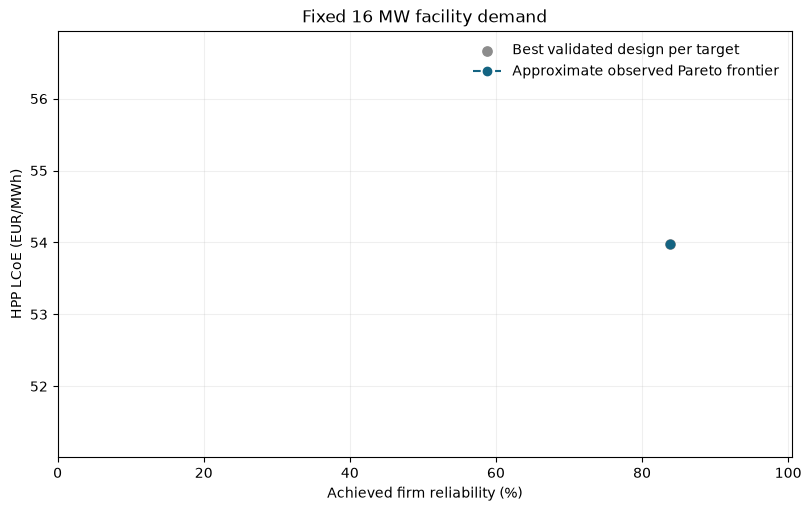

In [4]:
summary, figure = load_lcoe_reliability_experiment(
    experiment_dir, save_figures=bool(saved_experiment is not None and regenerate_saved_figures))
display(summary)
plt.show()
